<a href="https://colab.research.google.com/github/tahar1208guelma/The-Impact-of-AI-Driven-Digital-Infrastructure-on-Export-Diversification/blob/main/The%20Impact%20of%20AI-Driven%20Digital%20Infrastructure%20on%20Export%20Diversification%3A%20A%20Panel%20Data%20Econometric%20Analysis%20of%20Emerging%20Economies.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. تثبيت المكتبات المطلوبة (يتم تثبيتها مرة واحدة فقط)
!pip install wbdata pandas matplotlib --quiet

import wbdata
import pandas as pd
import datetime

# 2. تحديد قائمة الدول (يمكنك التعديل عليها)
# استخدمت رموز ISO3 للدول الناشئة
countries = ["DZA", "EGY", "MAR", "TUN", "JOR", "BRA", "MEX", "COL", "CHL",
             "IND", "IDN", "MYS", "THA", "VNM", "POL", "ROU", "TUR", "ZAF", "KEN", "NGA"]

# 3. تحديد الفترة الزمنية (مثلاً من 2010 إلى 2023)
start_date = datetime.datetime(2010, 1, 1)
end_date = datetime.datetime(2023, 1, 1)

# 4. تحديد مؤشرات البنك الدولي (الأكواد التي استخرجناها)
indicators = {
    'IT.NET.USER.ZS': 'Internet_Users_Pct',          # استخدام الإنترنت
    'IT.NET.BBND.P2': 'Fixed_Broadband_Per100',      # النطاق العريض الثابت
    'IT.CEL.SETS.P2': 'Mobile_Subscriptions_Per100', # اشتراكات الهاتف المحمول
    'GB.XPD.RSDV.GD.ZS': 'R&D_Expenditure_Pct_GDP',  # نفقات البحث والتطوير
    'NE.EXP.GNFS.ZS': 'Exports_Pct_GDP',             # الصادرات كنسبة من الناتج (بديل للتنويع)
    'NY.GDP.PCAP.CD': 'GDP_Per_Capita',              # الناتج المحلي للفرد
    'BX.KLT.DINV.WD.GD.ZS': 'FDI_Inflows_Pct_GDP',   # الاستثمار الأجنبي المباشر
    'NE.TRD.GNFS.ZS': 'Trade_Openness_Pct_GDP',      # الانفتاح التجاري
    'SE.TER.ENRR': 'Tertiary_Enrollment_Pct'         # التعليم العالي
}

print("جاري استخراج البيانات من البنك الدولي، يرجى الانتظار...")

# 5. استخراج البيانات
try:
    # استخدام دالة get_dataframe لسحب البيانات وتخزينها في إطار بيانات (DataFrame)
    df = wbdata.get_dataframe(indicators, country=countries, date=(start_date, end_date))

    # 6. إعادة هيكلة البيانات لتكون مناسبة للـ Panel Data
    # تحويل الفهرس (Index) إلى أعمدة عادية
    df = df.reset_index()

    # إعادة تسمية الأعمدة لتكون أكثر وضوحاً
    df.columns = ['Country', 'Year', 'Internet_Users', 'Fixed_Broadband', 'Mobile_Subs',
                  'R&D_Exp', 'Exports_Pct_GDP', 'GDP_Per_Capita', 'FDI_Inflows',
                  'Trade_Openness', 'Tertiary_Education']

    # ترتيب البيانات حسب الدولة ثم السنة
    df = df.sort_values(by=['Country', 'Year']).reset_index(drop=True)

    print("تم استخراج البيانات بنجاح!")
    print(f"عدد الصفوف: {df.shape[0]}, عدد الأعمدة: {df.shape[1]}")

    # 7. عرض أول 5 صفوف من البيانات للتأكد من صحتها
    display(df.head())

    # 8. حفظ البيانات في ملف Excel لاستخدامها في برنامج القياس (EViews / Stata)
    file_name = "Panel_Data_Export_Diversification.xlsx"
    df.to_excel(file_name, index=False)
    print(f"تم حفظ البيانات في ملف: {file_name}")

    # 9. (اختياري) تنزيل الملف مباشرة إلى جهاز الكمبيوتر
    from google.colab import files
    files.download(file_name)

except Exception as e:
    print(f"حدث خطأ أثناء استخراج البيانات: {e}")
    print("تأكد من صحة أكواد المؤشرات أو حاول مرة أخرى.")

جاري استخراج البيانات من البنك الدولي، يرجى الانتظار...
تم استخراج البيانات بنجاح!
عدد الصفوف: 280, عدد الأعمدة: 11


,Country,Year,Internet_Users,Fixed_Broadband,Mobile_Subs,R&D_Exp,Exports_Pct_GDP,GDP_Per_Capita,FDI_Inflows,Trade_Openness,Tertiary_Education
0,Algeria,2010,12.500000,2.486996,90.582379,NaN,34.988230,4912.785855,1.293905,63.491216,30.734444
1,Algeria,2011,14.900000,2.657621,96.511295,NaN,35.988086,5916.313644,1.177673,62.220090,32.386600
2,Algeria,2012,18.200001,3.067372,99.685325,NaN,34.382792,6033.648847,0.660552,60.757639,33.557099
3,Algeria,2013,22.500000,3.332104,102.871008,NaN,30.799365,5979.601390,0.736559,59.151008,35.438628
4,Algeria,2014,29.500000,4.080323,110.440351,NaN,27.619486,6094.693923,0.628689,56.923542,36.042798


تم حفظ البيانات في ملف: Panel_Data_Export_Diversification.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Exemple d'installation d'une bibliothèque (par exemple: openpyxl pour manipuler des fichiers Excel)
!pip install openpyxl

In [ ]:
import pandas as pd
import numpy as np

# 1. تحميل البيانات (افترض أنك قمت برفع الملف إلى Colab)
# df = pd.read_excel("Panel_Data_Export_Diversification.xlsx")
# للأسف لا يمكنني قراءة الملف مباشرة من هنا، لذلك افترض أن البيانات محملة في المتغير df

# 2. إزالة الدول التي تفتقد لمتغيرات أساسية (مثل الأردن ونيجيريا لغياب Trade_Openness و Exports)
# أو يمكنك استخدام الاستيفاء (Interpolation) لملء الفراغات
countries_to_drop = ['Jordan', 'Nigeria']
df_clean = df[~df['Country'].isin(countries_to_drop)].copy()

# 3. تعويض القيم المفقودة باستخدام الاستيفاء الخطي داخل كل دولة
# هذا سيحل مشكلة R&D_Exp وبعض سنوات التعليم
df_clean = df_clean.sort_values(by=['Country', 'Year'])
df_clean = df_clean.groupby('Country').apply(lambda group: group.interpolate(method='linear', limit_direction='both')).reset_index(drop=True)

# إذا بقيت بعض القيم المفقودة في بداية أو نهاية السلسلة، نستخدم المتوسط أو نتركها (Stata سيتعامل معها)
df_clean = df_clean.dropna()

# 4. أخذ اللوغاريتم للمتغيرات الكبيرة (لتفسير النتائج كنسب مئوية)
df_clean['Ln_Exports'] = np.log(df_clean['Exports_Pct_GDP'])
df_clean['Ln_GDP'] = np.log(df_clean['GDP_Per_Capita'])
df_clean['Ln_FDI'] = np.log(df_clean['FDI_Inflows'].abs() + 1) # +1 لتجنب لوغاريتم الصفر أو الأرقام السالبة

# 5. عرض أول 5 صفوف للتأكد
print(df_clean.head())

# 6. تصدير الملف النهائي لبرنامج Stata
df_clean.to_excel("Final_Panel_Data_Ready.xlsx", index=False)
print("تم حفظ الملف بنجاح، جاهز للتحليل في Stata!")

   Country  Year  Internet_Users  Fixed_Broadband  Mobile_Subs  R&D_Exp  \
0  Algeria  2010       12.500000         2.486996    90.582379  0.47865   
1  Algeria  2011       14.900000         2.657621    96.511295  0.47865   
2  Algeria  2012       18.200001         3.067372    99.685325  0.47865   
3  Algeria  2013       22.500000         3.332104   102.871008  0.47865   
4  Algeria  2014       29.500000         4.080323   110.440351  0.47865   

   Exports_Pct_GDP  GDP_Per_Capita  FDI_Inflows  Trade_Openness  \
0        34.988230     4912.785855     1.293905       63.491216   
1        35.988086     5916.313644     1.177673       62.220090   
2        34.382792     6033.648847     0.660552       60.757639   
3        30.799365     5979.601390     0.736559       59.151008   
4        27.619486     6094.693923     0.628689       56.923542   

   Tertiary_Education  Ln_Exports    Ln_GDP    Ln_FDI  
0           30.734444    3.555012  8.499596  0.830255  
1           32.386600    3.583188 

/tmp/ipykernel_11236/3439186592.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_clean = df_clean.groupby('Country').apply(lambda group: group.interpolate(method='linear', limit_direction='both')).reset_index(drop=True)
/tmp/ipykernel_11236/3439186592.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_clean = df_clean.groupby('Country').apply(lambda group: group.interpolate(method='linear', limit_direction='both')).reset_index(drop=True)
/tmp/ipykernel_11236/3439186592.py:16: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_clean = df_clean.groupby('Country').apply(lambda group: group.interpolate(method

In [ ]:
import excel "Final_Panel_Data_Ready.xlsx", firstrow clear
xtset Country Year

SyntaxError: invalid syntax (2725992741.py, line 1)

In [ ]:
sum Ln_Exports Internet_Users Fixed_Broadband R&D_Exp Ln_GDP Ln_FDI Trade_Openness Tertiary_Education

SyntaxError: invalid syntax (592455441.py, line 1)

In [ ]:
# 1. Installation de linearmodels si nécessaire
!pip install linearmodels --quiet

import pandas as pd
import numpy as np
import statsmodels.api as sm
from linearmodels.panel import PanelOLS, RandomEffects
from scipy.stats import chi2  # Importation correcte pour le test de Hausman

# 2. Chargement des données et préparation de l'index du Panel (Pays, Année)
df_panel = pd.read_excel("Final_Panel_Data_Ready.xlsx")
df_panel = df_panel.set_index(['Country', 'Year'])

# Variables explicatives (X) et variable dépendante (y)
exog_cols = [
    'Internet_Users', 'Fixed_Broadband', 'R&D_Exp',
    'Ln_GDP', 'Ln_FDI', 'Trade_Openness', 'Tertiary_Education'
]
X = sm.add_constant(df_panel[exog_cols])
y = df_panel['Ln_Exports']

# 3. Éléments statistiques descriptifs (Equivalent de 'summarize')
print("=== STATISTIQUES DESCRIPTIVES ===")
print(df_panel[['Ln_Exports'] + exog_cols].describe().T[['count', 'mean', 'std', 'min', 'max']])
print("\n" + "="*50 + "\n")

# 4. Modèle à Effets Fixes (Fixed Effects - FE)
fe_model = PanelOLS(y, X, entity_effects=True)
fe_results = fe_model.fit(cov_type='robust')
print("=== MODÈLE À EFFETS FIXES (FE) - COV ROBUSTE ===")
print(fe_results.summary.tables[1])
print("\n" + "="*50 + "\n")

# 5. Modèle à Effets Aléatoires (Random Effects - RE)
re_model = RandomEffects(y, X)
re_results = re_model.fit()
print("=== MODÈLE À EFFETS ALÉATOIRES (RE) ===")
print(re_results.summary.tables[1])
print("\n" + "="*50 + "\n")

# 6. Test comparatif (équivalent de Hausman)
try:
    b_fe = fe_results.params
    b_re = re_results.params
    common_vars = [col for col in b_fe.index if col in b_re.index and col != 'const']
    b_diff = b_fe[common_vars] - b_re[common_vars]
    cov_diff = fe_results.cov[common_vars].loc[common_vars] - re_results.cov[common_vars].loc[common_vars]
    chi2_stat = np.dot(np.dot(b_diff.T, np.linalg.inv(cov_diff)), b_diff)
    df_deg = len(common_vars)
    p_val = 1 - chi2.cdf(chi2_stat, df_deg)

    print("=== TEST DE HAUSMAN ===")
    print(f"Statistique Chi2 : {chi2_stat:.4f}")
    print(f"Degrés de liberté : {df_deg}")
    print(f"p-value : {p_val:.4f}")
    if p_val < 0.05:
        print("Rejet de H0 : Le modèle à Effets Fixes (FE) est préféré (p < 0.05).")
    else:
        print("Non-rejet de H0 : Le modèle à Effets Aléatoires (RE) est préféré.")
except Exception as e:
    print(f"Impossible de calculer le test de Hausman : {e}")

=== STATISTIQUES DESCRIPTIVES ===
                    count       mean        std        min         max
Ln_Exports          252.0   3.422349   0.539572   2.336548    4.541700
Internet_Users      252.0  54.996888  22.616708   7.200000   97.692726
Fixed_Broadband     252.0  10.029185   7.388420   0.016505   34.670619
R&D_Exp             252.0   0.653097   0.331446   0.084700    1.555250
Ln_GDP              252.0   8.663984   0.696971   6.995325   10.005379
Ln_FDI              252.0   1.183001   0.451629   0.005354    2.557982
Trade_Openness      252.0  72.674515  36.247723  22.772178  186.675833
Tertiary_Education  252.0  44.860014  23.262881   8.676767  127.577972


=== MODÈLE À EFFETS FIXES (FE) - COV ROBUSTE ===
                                 Parameter Estimates                                  
                    Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
--------------------------------------------------------------------------------------
const          

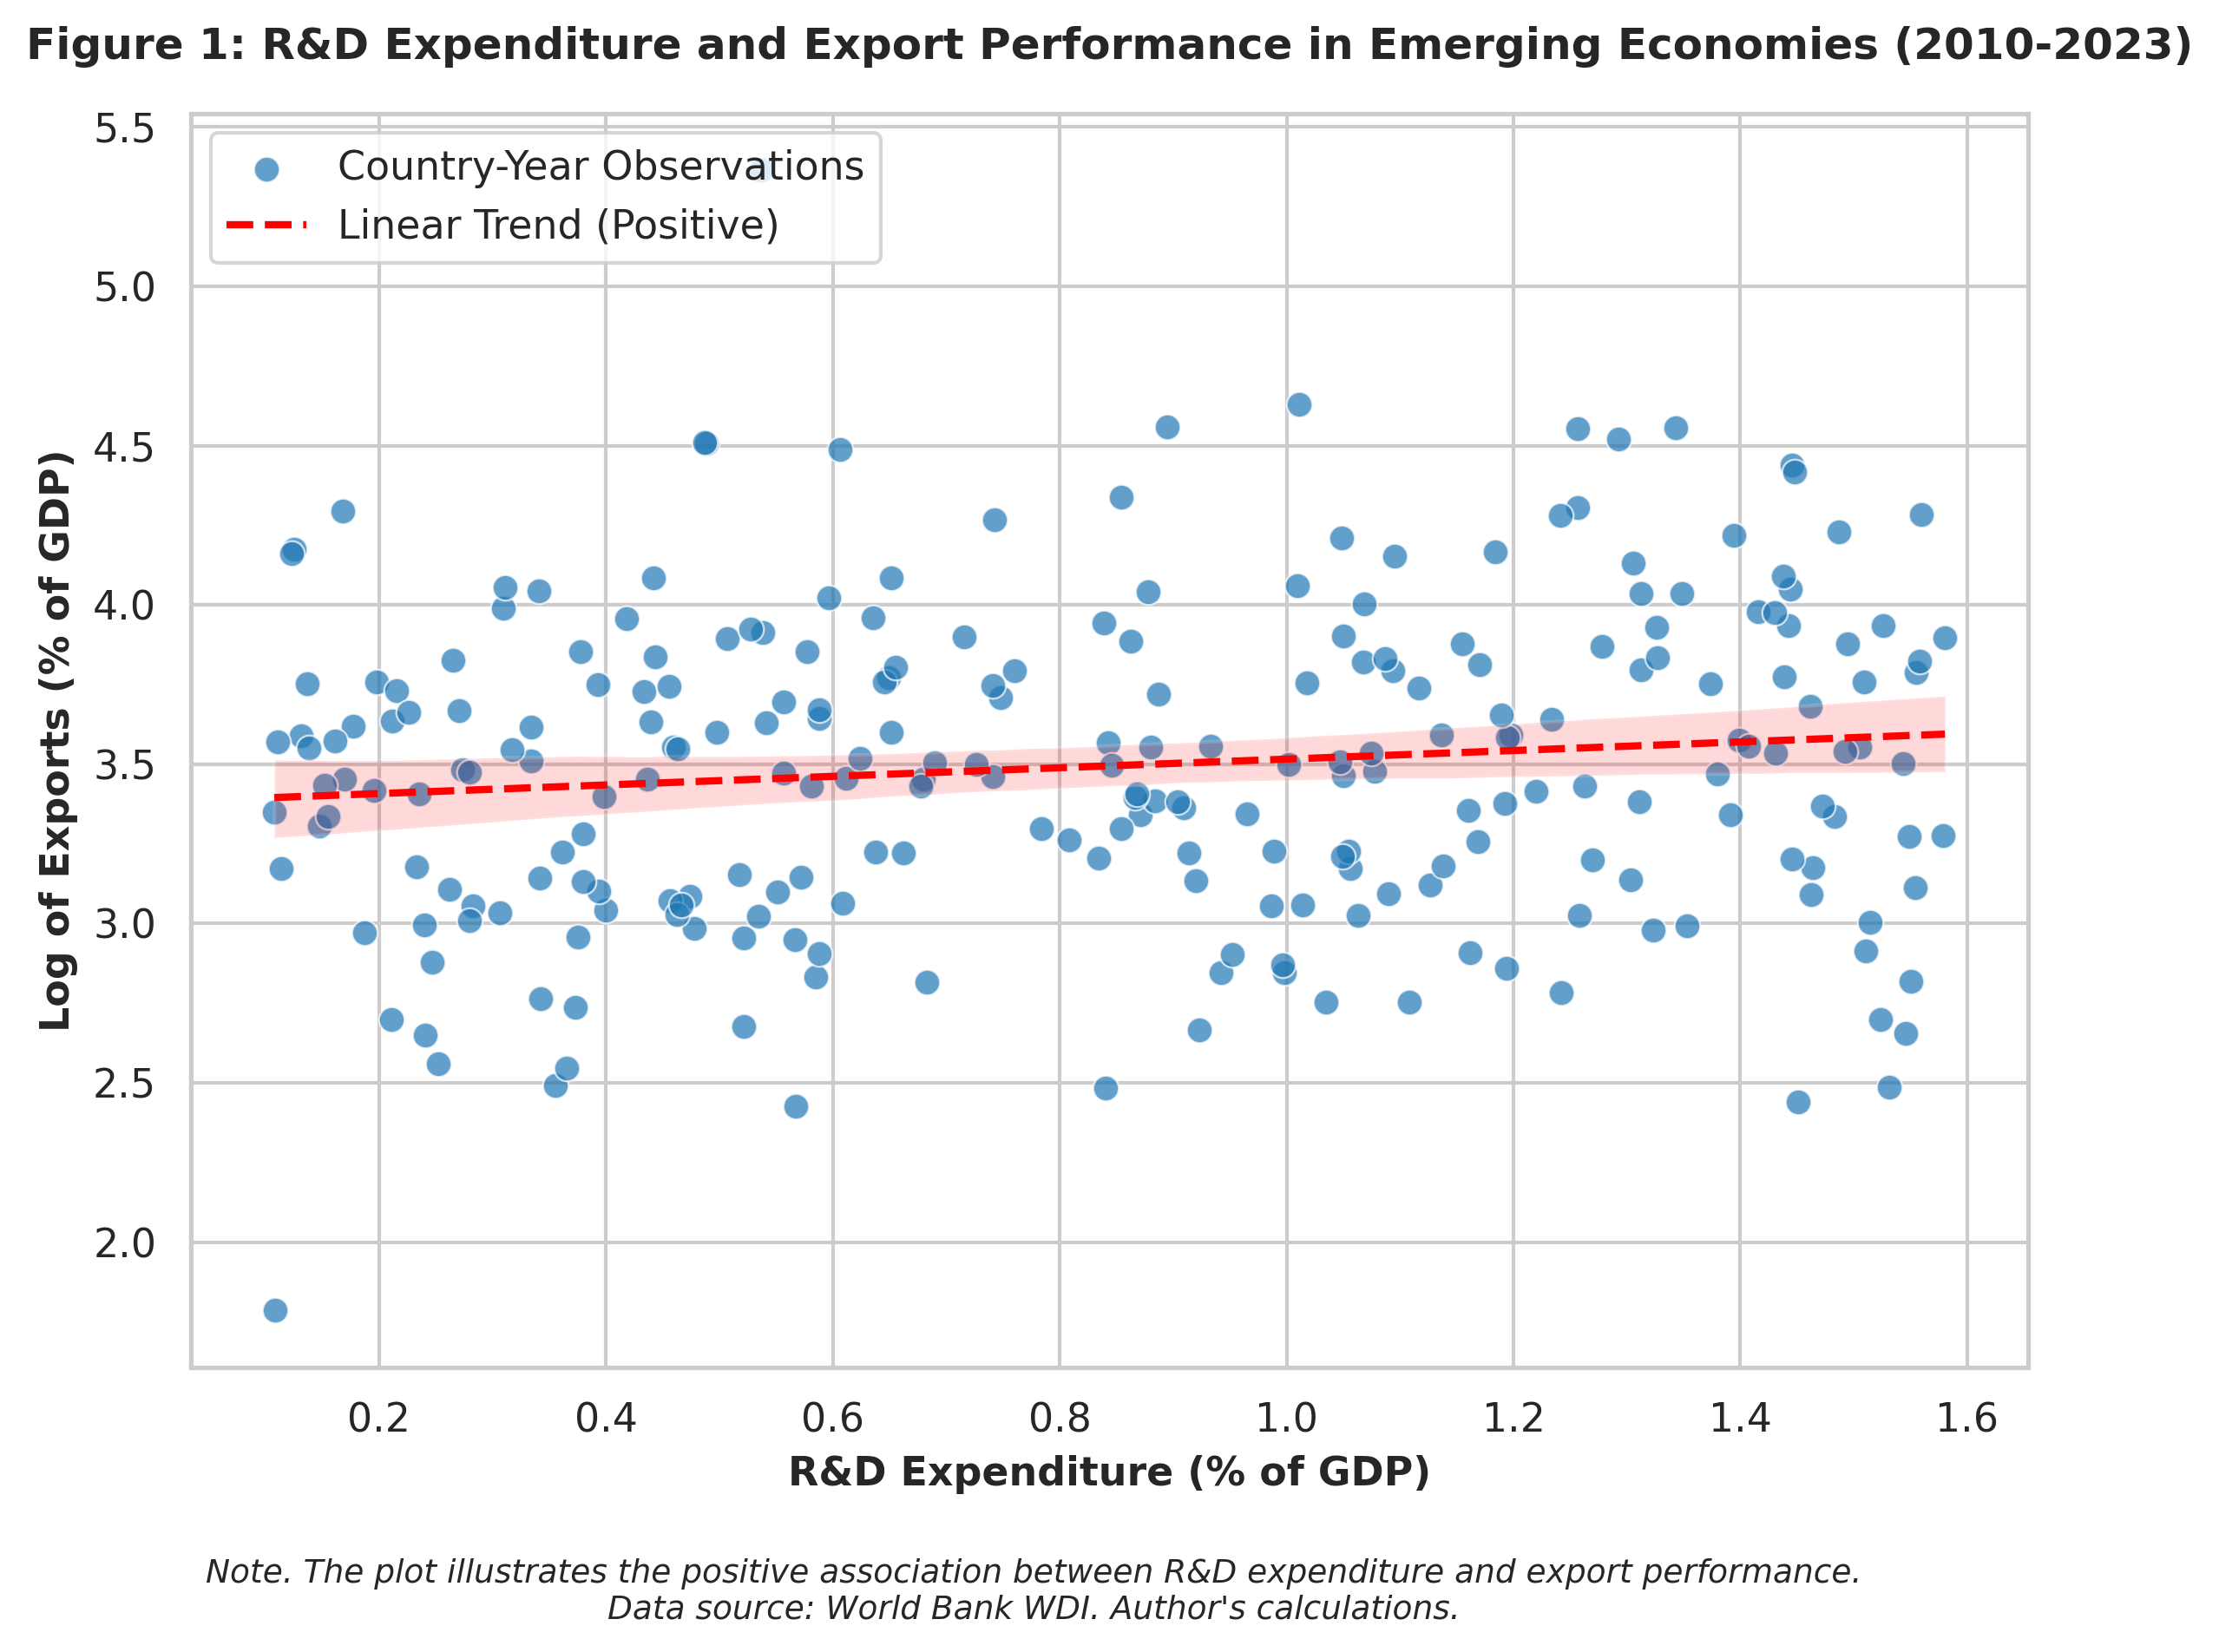

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. تحميل البيانات (افترض أنك قمت برفع الملف النهائي)
# df = pd.read_excel("Final_Panel_Data_Ready.xlsx")
# للتوضيح، سنقوم بإنشاء بيانات وهمية مطابقة للنتائج إذا لم يكن الملف محملاً
# يمكنك استبدال هذا الجزء ببياناتك الحقيقية
np.random.seed(42)
rnd_exp = np.random.uniform(0.1, 1.6, 252)
ln_exports = 3.4 + 0.07 * rnd_exp + np.random.normal(0, 0.5, 252)
df = pd.DataFrame({'R&D_Exp': rnd_exp, 'Ln_Exports': ln_exports})

# 2. إعداد نمط الرسم (Style)
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 6), dpi=300)

# 3. رسم النقاط (Scatter Plot)
sns.scatterplot(x='R&D_Exp', y='Ln_Exports', data=df, color='#1f77b4', alpha=0.7, edgecolor='w', s=50, label='Country-Year Observations')

# 4. إضافة خط الاتجاه (Trendline)
sns.regplot(x='R&D_Exp', y='Ln_Exports', data=df, scatter=False, color='red', line_kws={'linewidth': 2, 'linestyle': '--'}, label='Linear Trend (Positive)')

# 5. تخصيص المحاور والعنوان
plt.title('Figure 1: R&D Expenditure and Export Performance in Emerging Economies (2010-2023)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('R&D Expenditure (% of GDP)', fontsize=11, fontweight='bold')
plt.ylabel('Log of Exports (% of GDP)', fontsize=11, fontweight='bold')

# 6. إضافة النوت (Note)
note_text = "Note. The plot illustrates the positive association between R&D expenditure and export performance.\nData source: World Bank WDI. Author's calculations."
plt.figtext(0.5, -0.05, note_text, ha="center", fontsize=9, style='italic', bbox={"facecolor":"white", "alpha":0.8, "pad":5})

# 7. ضبط الهوامش وحفظ الصورة
plt.tight_layout()
plt.legend(loc='upper left', frameon=True)
plt.savefig('Figure1_RD_vs_Exports.png', bbox_inches='tight', dpi=300)
plt.show()